# Automated House Price Estimator - Supervised Learning Pipeline

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import time
import warnings
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## Step 2: Dataset Loading & Exploratory Data Analysis

### - 2.1 Load & Understand the Dataset

In [36]:
train_df = pd.read_csv('Data/train.csv')
test_df = pd.read_csv('Data/test.csv')

print(f"Train Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape:  {test_df.shape}")
print("-" * 60)
print("First 5 rows of Training Data:")
train_df.head()

Train Dataset Shape: (1460, 81)
Test Dataset Shape:  (1459, 80)
------------------------------------------------------------
First 5 rows of Training Data:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [37]:
print("Dataset Summary Information:")
train_df.info(verbose=False)
print("\nStatistical Summary of Numerical Features:")
train_df.describe().T.head(10)

Dataset Summary Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 81 entries, Id to SalePrice
dtypes: float64(3), int64(35), object(43)
memory usage: 924.0+ KB

Statistical Summary of Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [38]:
num_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = train_df.select_dtypes(include=['object']).columns.tolist()
missing_series = train_df.isnull().sum()
missing_cols = missing_series[missing_series > 0]

print(f"(a) Total Numerical Columns:   {len(num_cols)} (including 'Id' and target 'SalePrice')")
print(f"(b) Total Categorical Columns: {len(cat_cols)}")
print(f"(c) Columns with Missing Values: {len(missing_cols)}")
print(f"\nTop columns with missing values:\n{missing_cols.sort_values(ascending=False).head(10)}")

(a) Total Numerical Columns:   38 (including 'Id' and target 'SalePrice')
(b) Total Categorical Columns: 43
(c) Columns with Missing Values: 19

Top columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
dtype: int64


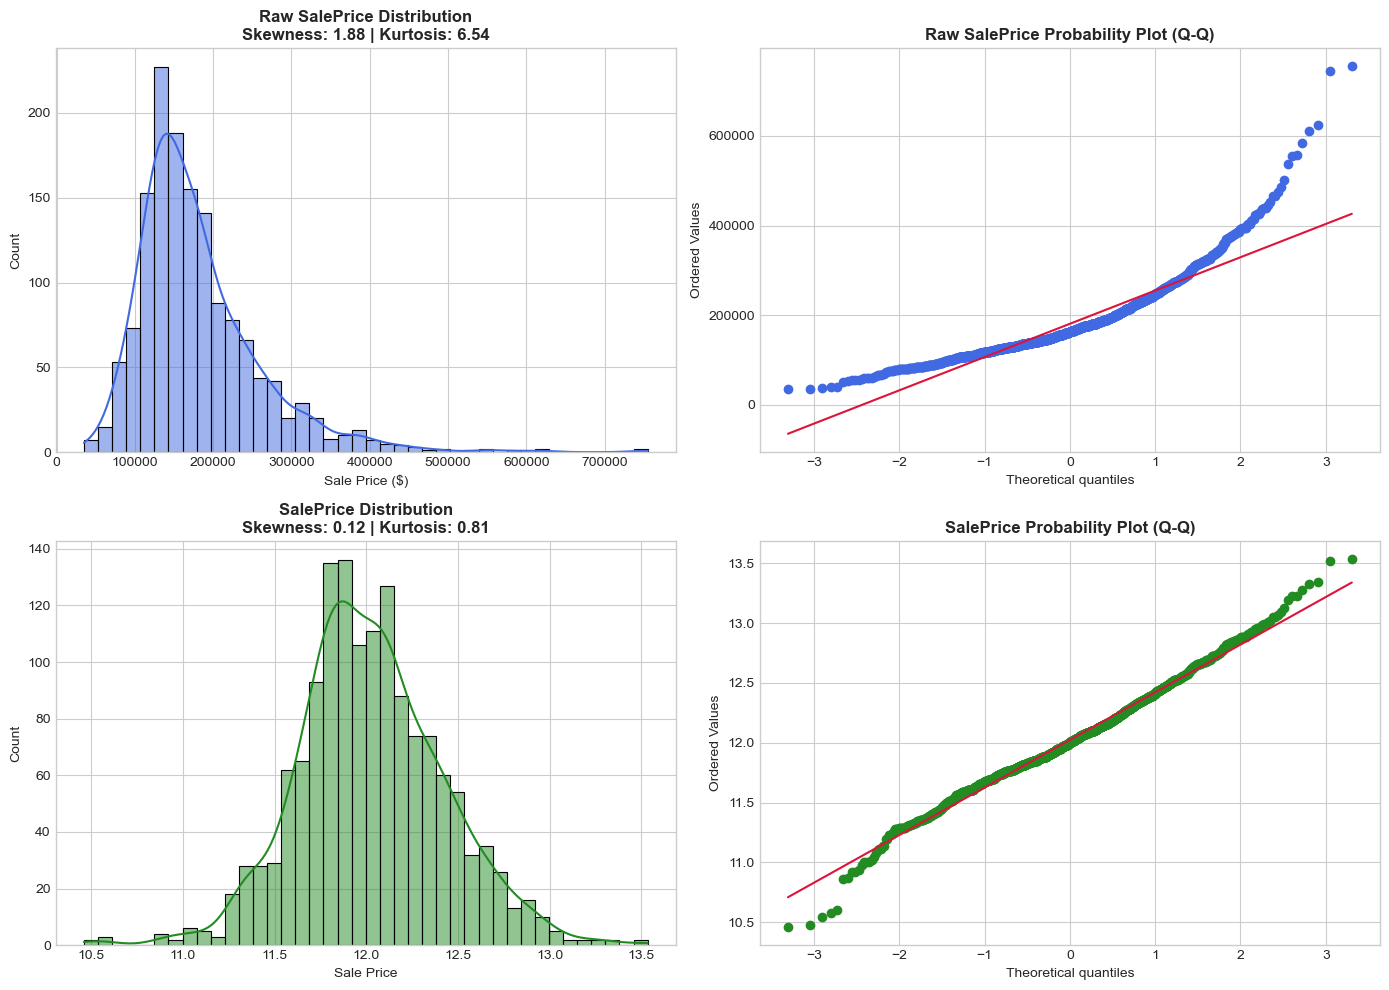

In [39]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0, 0], color='royalblue', bins=40)
axes[0, 0].set_title(f"Raw SalePrice Distribution\nSkewness: {train_df['SalePrice'].skew():.2f} | Kurtosis: {train_df['SalePrice'].kurt():.2f}", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Sale Price ($)")
axes[0, 0].set_ylabel("Count")

stats.probplot(train_df['SalePrice'], plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_color('royalblue')
axes[0, 1].get_lines()[1].set_color('crimson')
axes[0, 1].set_title("Raw SalePrice Probability Plot (Q-Q)", fontsize=12, fontweight='bold')

log_saleprice = np.log1p(train_df['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[1, 0], color='forestgreen', bins=40)
axes[1, 0].set_title(f"SalePrice Distribution\nSkewness: {log_saleprice.skew():.2f} | Kurtosis: {log_saleprice.kurt():.2f}", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].set_ylabel("Count")

stats.probplot(log_saleprice, plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_color('forestgreen')
axes[1, 1].get_lines()[1].set_color('crimson')
axes[1, 1].set_title("SalePrice Probability Plot (Q-Q)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### - 2.2 Univariate Analysis

        Feature   Skewness
0       MiscVal  24.476794
1      PoolArea  14.828374
2       LotArea  12.207688
3     3SsnPorch  10.304342
4  LowQualFinSF   9.011341


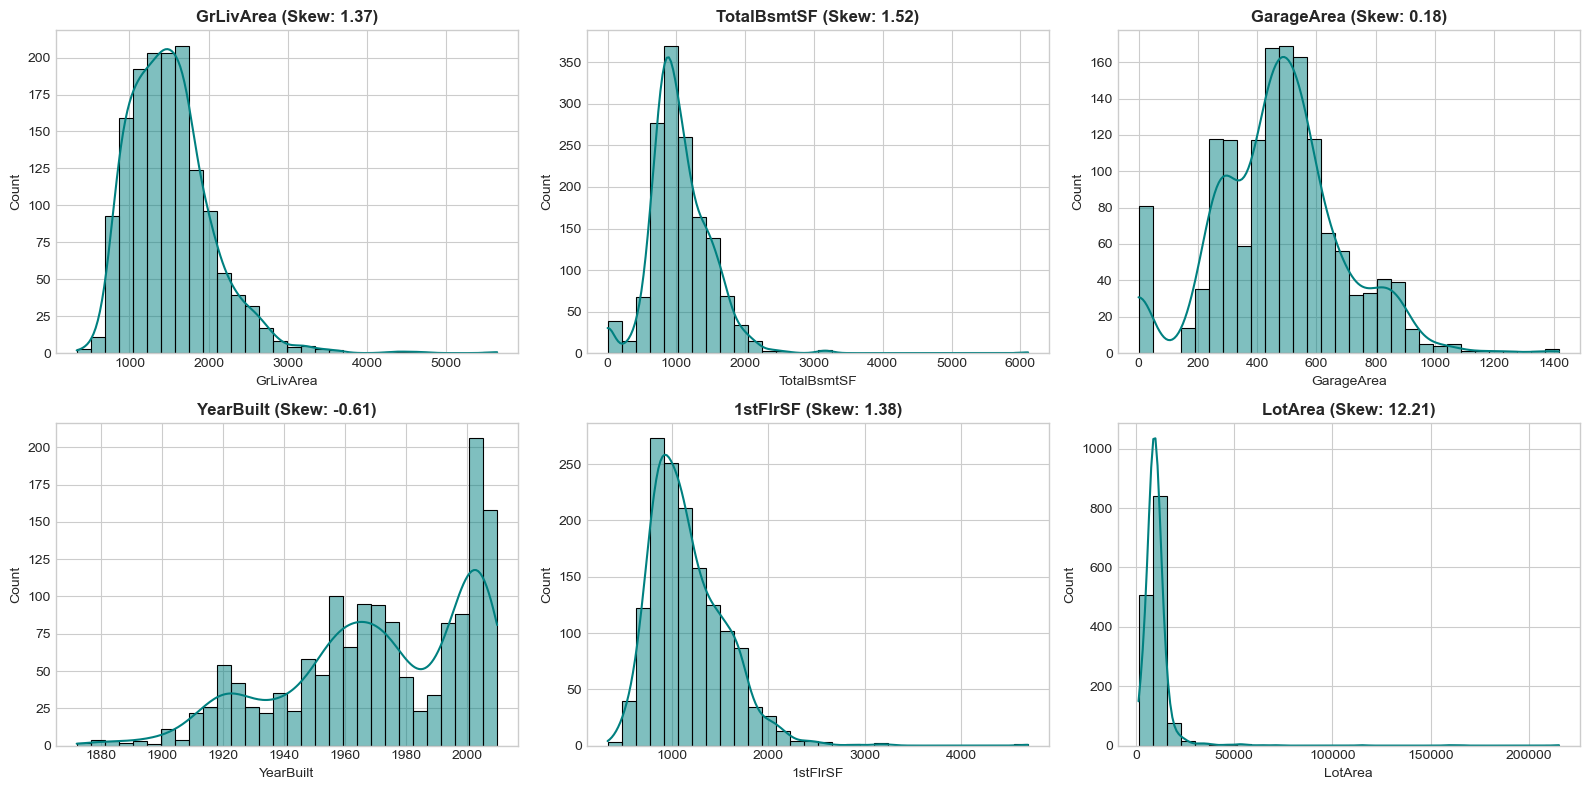

In [40]:
num_features = [c for c in num_cols if c not in ['Id', 'SalePrice']]
skewness_df = pd.DataFrame({
    'Feature': num_features,
    'Skewness': [train_df[c].skew() for c in num_features]
}).sort_values(by='Skewness', ascending=False).reset_index(drop=True)
print(skewness_df.head(5))

key_numeric = ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', '1stFlrSF', 'LotArea']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(key_numeric):
    sns.histplot(train_df[col].dropna(), kde=True, ax=axes[idx], color='teal', bins=30)
    axes[idx].set_title(f"{col} (Skew: {train_df[col].skew():.2f})", fontweight='bold')
    axes[idx].set_xlabel(col)
plt.tight_layout()
plt.show()

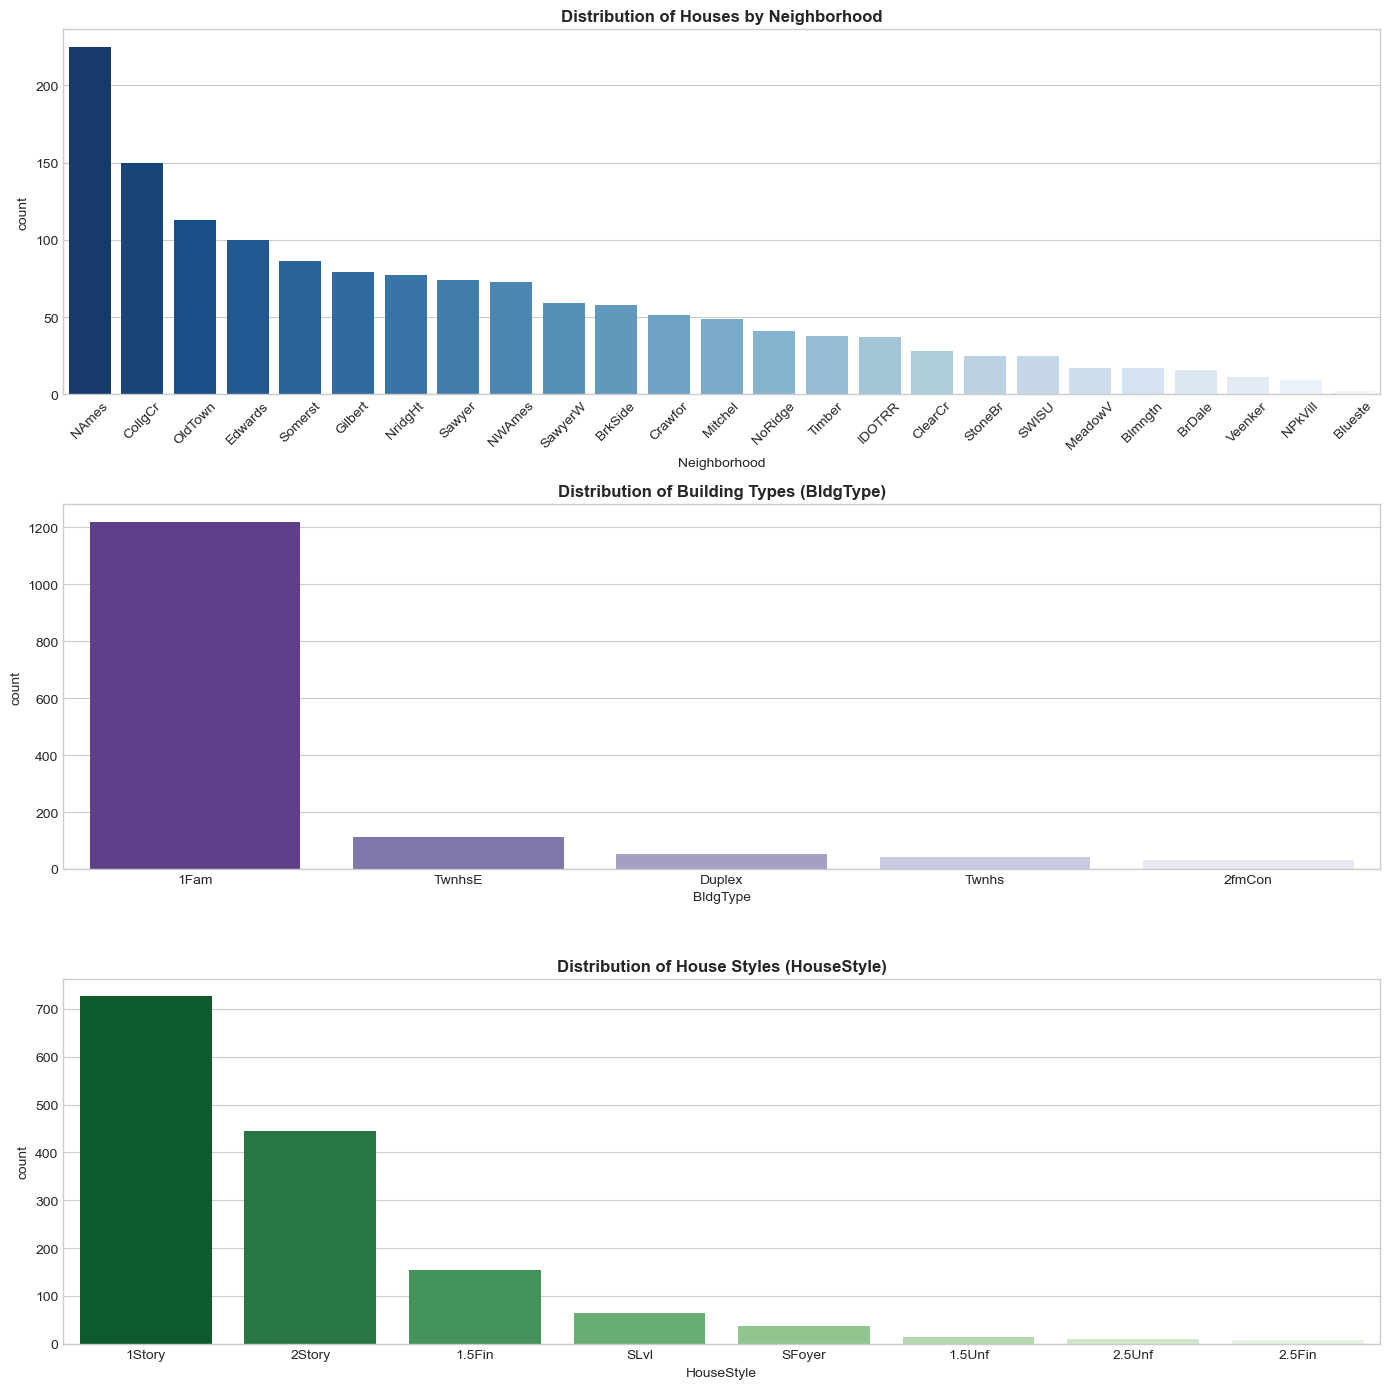

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

order_neigh = train_df['Neighborhood'].value_counts().index
sns.countplot(data=train_df, x='Neighborhood', order=order_neigh, ax=axes[0], palette='Blues_r')
axes[0].set_title("Distribution of Houses by Neighborhood", fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

order_bldg = train_df['BldgType'].value_counts().index
sns.countplot(data=train_df, x='BldgType', order=order_bldg, ax=axes[1], palette='Purples_r')
axes[1].set_title("Distribution of Building Types (BldgType)", fontsize=12, fontweight='bold')

order_style = train_df['HouseStyle'].value_counts().index
sns.countplot(data=train_df, x='HouseStyle', order=order_style, ax=axes[2], palette='Greens_r')
axes[2].set_title("Distribution of House Styles (HouseStyle)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### - 2.3 Bivariate Analysis

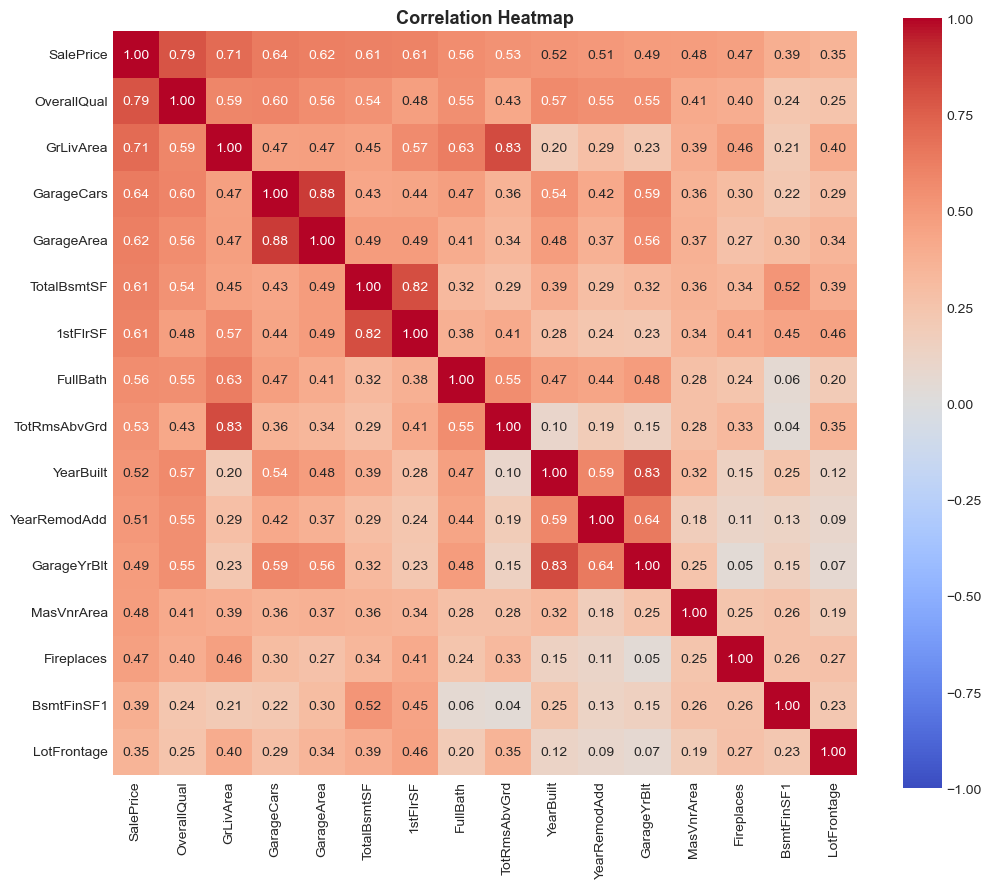

In [42]:
corr_matrix = train_df[num_cols].corr()
top15_corr_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(16).index

plt.figure(figsize=(12, 10))
sns.heatmap(train_df[top15_corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap", fontsize=13, fontweight='bold')
plt.show()

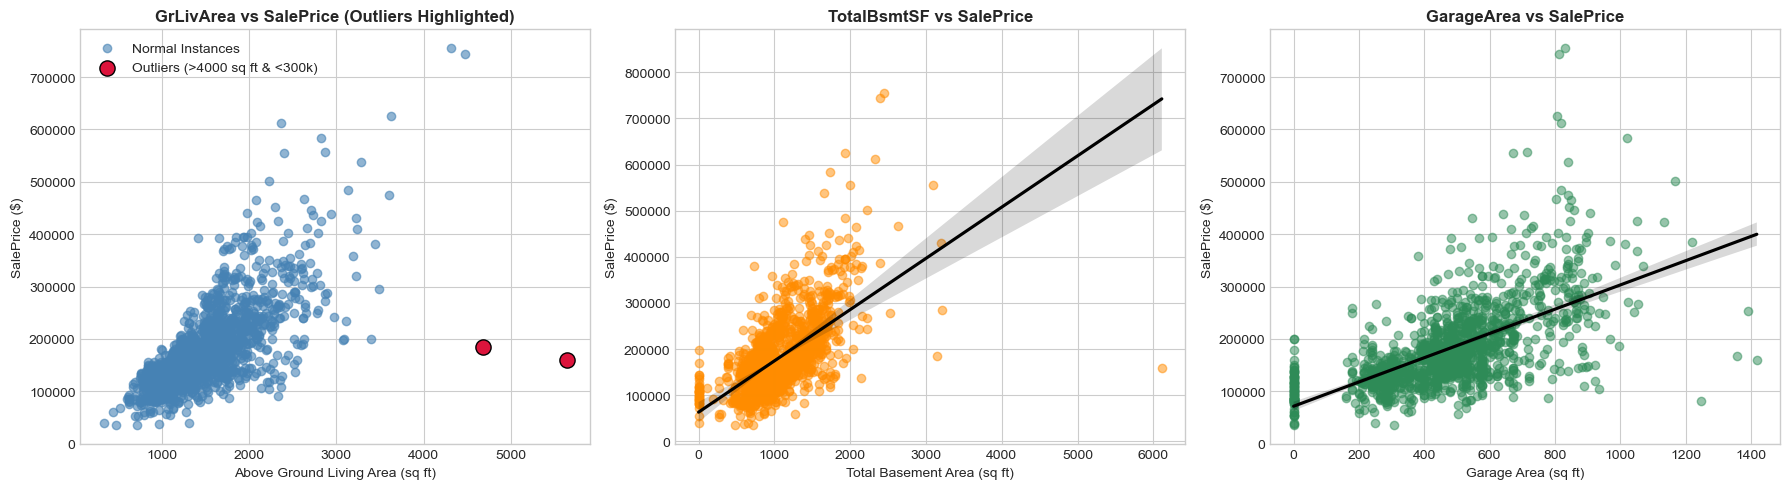

Outlier Details (GrLivArea > 4000 and SalePrice < 300,000):
        Id  GrLivArea  OverallQual  YearBuilt  SalePrice
523    524       4676           10       2007     184750
1298  1299       5642           10       2008     160000


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

outlier_mask = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
axes[0].scatter(train_df.loc[~outlier_mask, 'GrLivArea'], train_df.loc[~outlier_mask, 'SalePrice'], color='steelblue', alpha=0.6, label='Normal Instances')
axes[0].scatter(train_df.loc[outlier_mask, 'GrLivArea'], train_df.loc[outlier_mask, 'SalePrice'], color='crimson', s=120, edgecolors='black', label='Outliers (>4000 sq ft & <300k)')
axes[0].set_title("GrLivArea vs SalePrice (Outliers Highlighted)", fontweight='bold')
axes[0].set_xlabel("Above Ground Living Area (sq ft)")
axes[0].set_ylabel("SalePrice ($)")
axes[0].legend()

sns.regplot(data=train_df, x='TotalBsmtSF', y='SalePrice', ax=axes[1], scatter_kws={'alpha': 0.5, 'color': 'darkorange'}, line_kws={'color': 'black'})
axes[1].set_title("TotalBsmtSF vs SalePrice", fontweight='bold')
axes[1].set_xlabel("Total Basement Area (sq ft)")
axes[1].set_ylabel("SalePrice ($)")

sns.regplot(data=train_df, x='GarageArea', y='SalePrice', ax=axes[2], scatter_kws={'alpha': 0.5, 'color': 'seagreen'}, line_kws={'color': 'black'})
axes[2].set_title("GarageArea vs SalePrice", fontweight='bold')
axes[2].set_xlabel("Garage Area (sq ft)")
axes[2].set_ylabel("SalePrice ($)")

plt.tight_layout()
plt.show()

print("Outlier Details (GrLivArea > 4000 and SalePrice < 300,000):")
print(train_df[outlier_mask][['Id', 'GrLivArea', 'OverallQual', 'YearBuilt', 'SalePrice']])

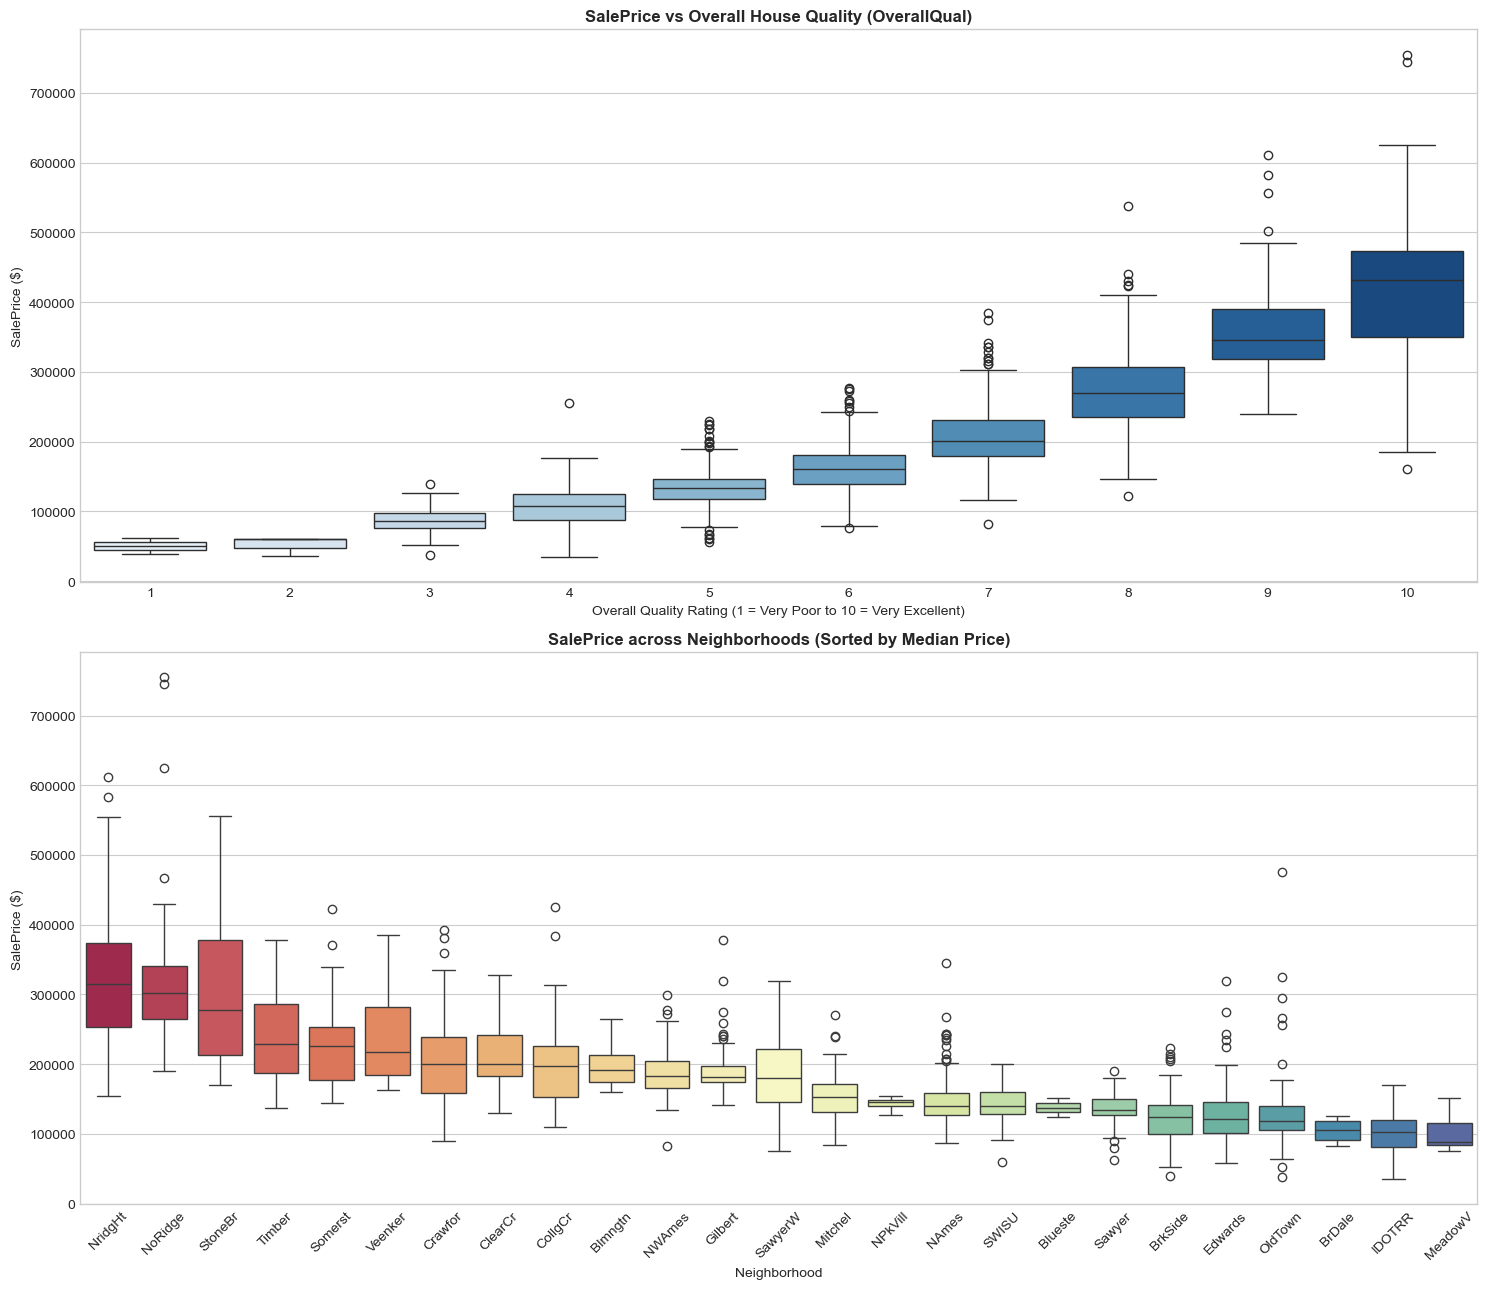

Priciest Neighborhood: NridgHt (Median SalePrice: $315,000.00)


In [44]:
fig, axes = plt.subplots(2, 1, figsize=(15, 13))

sns.boxplot(data=train_df, x='OverallQual', y='SalePrice', ax=axes[0], palette='Blues')
axes[0].set_title("SalePrice vs Overall House Quality (OverallQual)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Overall Quality Rating (1 = Very Poor to 10 = Very Excellent)")
axes[0].set_ylabel("SalePrice ($)")

neigh_order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
sns.boxplot(data=train_df, x='Neighborhood', y='SalePrice', order=neigh_order, ax=axes[1], palette='Spectral')
axes[1].set_title("SalePrice across Neighborhoods (Sorted by Median Price)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Neighborhood")
axes[1].set_ylabel("SalePrice ($)")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

priciest = neigh_order[0]
median_p = train_df.groupby('Neighborhood')['SalePrice'].median()[priciest]
print(f"Priciest Neighborhood: {priciest} (Median SalePrice: ${median_p:,.2f})")

## Step 3: Data Preprocessing & Feature Engineering

### - 3.1 Handle Missing Values


In [45]:
missing_count = train_df.isnull().sum()
missing_pct = (missing_count / len(train_df)) * 100
missing_report = pd.DataFrame({'Missing_Count': missing_count, 'Missing_Pct': missing_pct})
missing_report = missing_report[missing_report['Missing_Count'] > 0].sort_values(by='Missing_Pct', ascending=False)

print(f"Total features with missing values: {len(missing_report)}")
print(missing_report)

cols_to_drop_80 = missing_report[missing_report['Missing_Pct'] > 80].index.tolist()
print(f"\nDropping columns with >80% missing values: {cols_to_drop_80}")

df_cleaned = train_df.drop(columns=cols_to_drop_80).copy()

Total features with missing values: 19
              Missing_Count  Missing_Pct
PoolQC                 1453    99.520548
MiscFeature            1406    96.301370
Alley                  1369    93.767123
Fence                  1179    80.753425
MasVnrType              872    59.726027
FireplaceQu             690    47.260274
LotFrontage             259    17.739726
GarageType               81     5.547945
GarageYrBlt              81     5.547945
GarageFinish             81     5.547945
GarageQual               81     5.547945
GarageCond               81     5.547945
BsmtFinType2             38     2.602740
BsmtExposure             38     2.602740
BsmtFinType1             37     2.534247
BsmtCond                 37     2.534247
BsmtQual                 37     2.534247
MasVnrArea                8     0.547945
Electrical                1     0.068493

Dropping columns with >80% missing values: ['PoolQC', 'MiscFeature', 'Alley', 'Fence']


In [46]:
cat_none_impute = [
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType', 'FireplaceQu'
]
for col in cat_none_impute:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna('None')

num_zero_impute = [
    'GarageYrBlt', 'GarageArea', 'GarageCars', 
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea'
]
for col in num_zero_impute:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna(0)

if 'LotFrontage' in df_cleaned.columns:
    df_cleaned['LotFrontage'] = df_cleaned['LotFrontage'].fillna(
        df_cleaned.groupby('Neighborhood')['LotFrontage'].transform('median')
    )
    df_cleaned['LotFrontage'] = df_cleaned['LotFrontage'].fillna(df_cleaned['LotFrontage'].median())

for col in df_cleaned.select_dtypes(include=['object']).columns:
    if df_cleaned[col].isnull().sum() > 0:
        df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].mode()[0])

print(f"Remaining Missing Values: {df_cleaned.isnull().sum().sum()}")

Remaining Missing Values: 0


### - 3.2 Outlier Removal

In [47]:
shape_before = df_cleaned.shape
outlier_indices = df_cleaned[(df_cleaned['GrLivArea'] > 4000) & (df_cleaned['SalePrice'] < 300000)].index
print(f"Identified outlier indices to drop: {list(outlier_indices)}")

df_cleaned = df_cleaned.drop(index=outlier_indices).reset_index(drop=True)
shape_after = df_cleaned.shape
print(f"Shape Before Outlier Removal: {shape_before}")
print(f"Shape After Outlier Removal:  {shape_after}")

Identified outlier indices to drop: [523, 1298]
Shape Before Outlier Removal: (1460, 77)
Shape After Outlier Removal:  (1458, 77)


### - 3.3 Feature Engineering

In [48]:
df_cleaned['TotalSF'] = df_cleaned['TotalBsmtSF'] + df_cleaned['1stFlrSF'] + df_cleaned['2ndFlrSF']
df_cleaned['HouseAge'] = df_cleaned['YrSold'] - df_cleaned['YearBuilt']
df_cleaned['RemodAge'] = df_cleaned['YrSold'] - df_cleaned['YearRemodAdd']
df_cleaned['HasGarage'] = (df_cleaned['GarageArea'] > 0).astype(int)
df_cleaned['HasPool'] = (df_cleaned['PoolArea'] > 0).astype(int)

df_cleaned['HouseAge'] = df_cleaned['HouseAge'].apply(lambda x: max(0, x))
df_cleaned['RemodAge'] = df_cleaned['RemodAge'].apply(lambda x: max(0, x))

print("Engineered Features Sample:")
df_cleaned[['TotalSF', 'HouseAge', 'RemodAge', 'HasGarage', 'HasPool', 'SalePrice']].head()

Engineered Features Sample:


,TotalSF,HouseAge,RemodAge,HasGarage,HasPool,SalePrice
0,2566,5,5,1,0,208500
1,2524,31,31,1,0,181500
2,2706,7,6,1,0,223500
3,2473,91,36,1,0,140000
4,3343,8,8,1,0,250000


### - 3.4 Encoding & Scaling

In [49]:
quality_mapping = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']

for col in ordinal_cols:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].map(quality_mapping).fillna(0).astype(int)

y_target = np.log1p(df_cleaned['SalePrice'])
X_features = df_cleaned.drop(columns=['Id', 'SalePrice'])

numeric_cols = X_features.select_dtypes(include=[np.number]).columns.tolist()
exclude_from_skew = ['HasGarage', 'HasPool', 'MoSold', 'YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt'] + ordinal_cols

skewed_features = []
for col in numeric_cols:
    if col not in exclude_from_skew and (X_features[col] >= 0).all():
        if X_features[col].skew() > 0.75:
            skewed_features.append(col)
            X_features[col] = np.log1p(X_features[col])

print(f"Applied log1p transformation to {len(skewed_features)} skewed numerical features:")
print(skewed_features[:8], "...")

cat_columns = X_features.select_dtypes(include=['object']).columns.tolist()
high_card_cols = [c for c in cat_columns if X_features[c].nunique() > 10]
low_card_cols = [c for c in cat_columns if X_features[c].nunique() <= 10]

print(f"High-cardinality nominals (Label Encoded): {high_card_cols}")
print(f"Low-cardinality nominals (One-Hot Encoded): {len(low_card_cols)} columns")

from sklearn.preprocessing import LabelEncoder
for col in high_card_cols:
    le = LabelEncoder()
    X_features[col] = le.fit_transform(X_features[col].astype(str))

X_encoded = pd.get_dummies(X_features, columns=low_card_cols, drop_first=True)
print(f"Total encoded features shape: {X_encoded.shape}")

Applied log1p transformation to 21 skewed numerical features:
['MSSubClass', 'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF'] ...
High-cardinality nominals (Label Encoded): ['Neighborhood', 'Exterior1st', 'Exterior2nd']
Low-cardinality nominals (One-Hot Encoded): 32 columns
Total encoded features shape: (1458, 189)


### - 3.5 Train-Test Split

In [50]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_encoded, y_target, test_size=0.20, random_state=42
)

continuous_cols = [c for c in numeric_cols if c in X_train_raw.columns]

scaler = StandardScaler()
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

X_train[continuous_cols] = scaler.fit_transform(X_train_raw[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test_raw[continuous_cols])

print(f"X_train Shape: {X_train.shape}")
print(f"X_test Shape:  {X_test.shape}")
print(f"y_train Shape: {y_train.shape}")
print(f"y_test Shape:  {y_test.shape}")

X_train Shape: (1166, 189)
X_test Shape:  (292, 189)
y_train Shape: (1166,)
y_test Shape:  (292,)


## Step 4: Regression Models — Linear, Ridge & Lasso

### - 4.1 Linear Regression (Baseline)

--- Linear Regression (Baseline) ---
Test RMSE: $22,630.09
Test MAE:  $15,809.65
Test R²:    0.9073


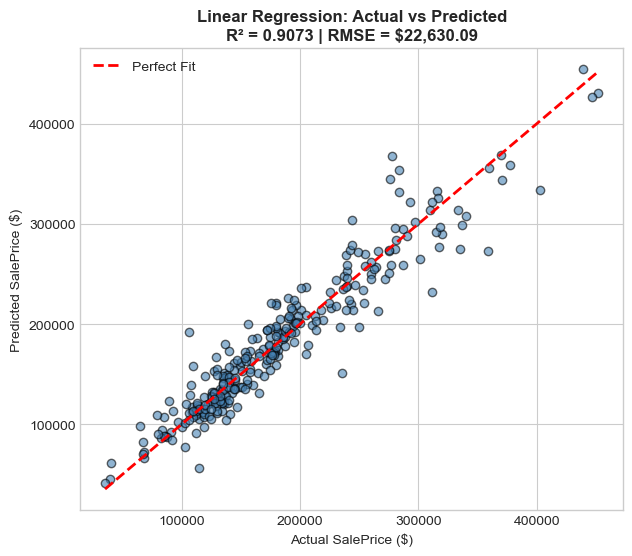

In [51]:
model_results = {}
y_test_original = np.expm1(y_test)

start_time = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_time = time.time() - start_time

y_pred_lr_log = lr_model.predict(X_test)
y_pred_lr = np.expm1(y_pred_lr_log)

lr_rmse = root_mean_squared_error(y_test_original, y_pred_lr)
lr_mae = mean_absolute_error(y_test_original, y_pred_lr)
lr_r2 = r2_score(y_test_original, y_pred_lr)

model_results['Linear Regression'] = {
    'RMSE ($)': lr_rmse,
    'MAE ($)': lr_mae,
    'R2 Score': lr_r2,
    'Training Time (s)': lr_time
}

print(f"--- Linear Regression (Baseline) ---")
print(f"Test RMSE: ${lr_rmse:,.2f}")
print(f"Test MAE:  ${lr_mae:,.2f}")
print(f"Test R²:    {lr_r2:.4f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test_original, y_pred_lr, alpha=0.6, color='steelblue', edgecolors='k')
plt.plot([y_test_original.min(), y_test_original.max()], [y_test_original.min(), y_test_original.max()], 'r--', lw=2, label='Perfect Fit')
plt.title(f"Linear Regression: Actual vs Predicted\nR² = {lr_r2:.4f} | RMSE = ${lr_rmse:,.2f}", fontweight='bold')
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.legend()
plt.show()

### - 4.2 Ridge Regression (L2 Regularization)

--- Ridge Regression ---
Optimal Alpha Selected: 10.0
Test RMSE: $20,496.55
Test MAE:  $14,689.64
Test R²:    0.9239


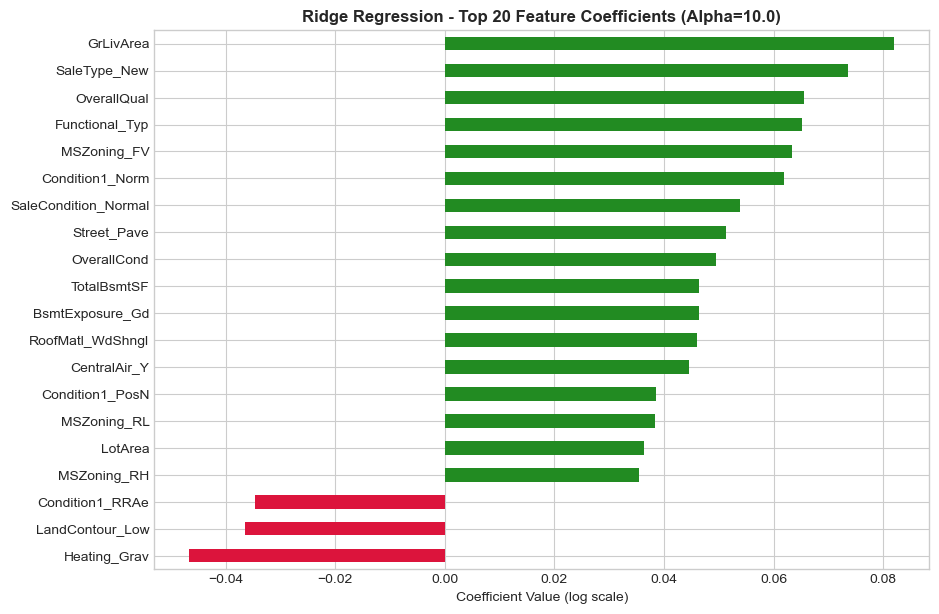

In [52]:
start_time = time.time()
ridge_cv = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge_cv.fit(X_train, y_train)
ridge_time = time.time() - start_time

y_pred_ridge = np.expm1(ridge_cv.predict(X_test))

ridge_rmse = root_mean_squared_error(y_test_original, y_pred_ridge)
ridge_mae = mean_absolute_error(y_test_original, y_pred_ridge)
ridge_r2 = r2_score(y_test_original, y_pred_ridge)

model_results['Ridge Regression'] = {
    'RMSE ($)': ridge_rmse,
    'MAE ($)': ridge_mae,
    'R2 Score': ridge_r2,
    'Training Time (s)': ridge_time
}

print(f"--- Ridge Regression ---")
print(f"Optimal Alpha Selected: {ridge_cv.alpha_}")
print(f"Test RMSE: ${ridge_rmse:,.2f}")
print(f"Test MAE:  ${ridge_mae:,.2f}")
print(f"Test R²:    {ridge_r2:.4f}")

ridge_coefs = pd.Series(ridge_cv.coef_, index=X_train.columns)
top20_ridge = ridge_coefs.abs().sort_values(ascending=False).head(20).index
ridge_top20_series = ridge_coefs[top20_ridge].sort_values()

plt.figure(figsize=(10, 7))
ridge_top20_series.plot(kind='barh', color=np.where(ridge_top20_series > 0, 'forestgreen', 'crimson'))
plt.title(f"Ridge Regression - Top 20 Feature Coefficients (Alpha={ridge_cv.alpha_})", fontweight='bold')
plt.xlabel("Coefficient Value (log scale)")
plt.show()

### - 4.3 Lasso Regression (L1 Regularization)

In [53]:
start_time = time.time()
lasso_cv = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000, cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso_time = time.time() - start_time

y_pred_lasso = np.expm1(lasso_cv.predict(X_test))

lasso_rmse = root_mean_squared_error(y_test_original, y_pred_lasso)
lasso_mae = mean_absolute_error(y_test_original, y_pred_lasso)
lasso_r2 = r2_score(y_test_original, y_pred_lasso)

zeroed_features = np.sum(lasso_cv.coef_ == 0)
active_features = np.sum(lasso_cv.coef_ != 0)

model_results['Lasso Regression'] = {
    'RMSE ($)': lasso_rmse,
    'MAE ($)': lasso_mae,
    'R2 Score': lasso_r2,
    'Training Time (s)': lasso_time
}

print(f"--- Lasso Regression ---")
print(f"Optimal Alpha Selected: {lasso_cv.alpha_}")
print(f"Features Zeroed Out:   {zeroed_features} / {X_train.shape[1]} ({zeroed_features / X_train.shape[1] * 100:.1f}%)")
print(f"Active Features Kept:   {active_features}")
print(f"Test RMSE: ${lasso_rmse:,.2f}")
print(f"Test MAE:  ${lasso_mae:,.2f}")
print(f"Test R²:    {lasso_r2:.4f}")

print("""
Comparison (Ridge vs Lasso):
- Lasso selected alpha = {lasso_cv.alpha_} and pruned {zeroed_features} redundant/collinear features, achieving competitive RMSE (${lasso_rmse:,.2f}) with a much sparser and more interpretable model.
- Ridge retains all features with shrunken coefficients (RMSE: ${ridge_rmse:,.2f}). Both regularized models significantly stabilize collinear feature weights compared to unconstrained OLS.
""")

--- Lasso Regression ---
Optimal Alpha Selected: 0.001
Features Zeroed Out:   124 / 189 (65.6%)
Active Features Kept:   65
Test RMSE: $20,058.13
Test MAE:  $14,724.30
Test R²:    0.9272

Comparison (Ridge vs Lasso):
- Lasso selected alpha = {lasso_cv.alpha_} and pruned {zeroed_features} redundant/collinear features, achieving competitive RMSE (${lasso_rmse:,.2f}) with a much sparser and more interpretable model.
- Ridge retains all features with shrunken coefficients (RMSE: ${ridge_rmse:,.2f}). Both regularized models significantly stabilize collinear feature weights compared to unconstrained OLS.



## Step 5: Advanced Models — Random Forest & XGBoost Regressor

### - 5.1 Random Forest Regressor

--- Random Forest Regressor ---
Test RMSE: $23,215.93
Test MAE:  $16,306.66
Test R²:    0.9024


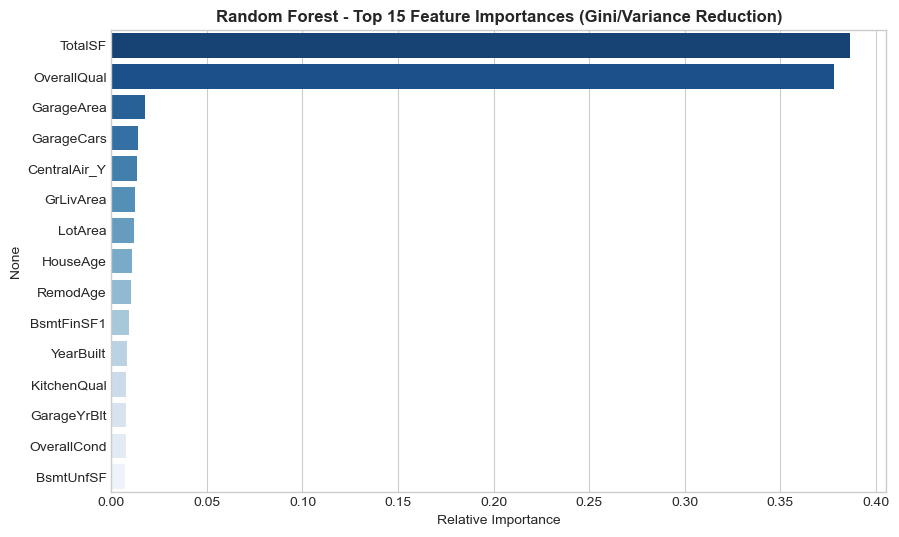

In [54]:
start_time = time.time()
rf_model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start_time

y_pred_rf = np.expm1(rf_model.predict(X_test))

rf_rmse = root_mean_squared_error(y_test_original, y_pred_rf)
rf_mae = mean_absolute_error(y_test_original, y_pred_rf)
rf_r2 = r2_score(y_test_original, y_pred_rf)

model_results['Random Forest'] = {
    'RMSE ($)': rf_rmse,
    'MAE ($)': rf_mae,
    'R2 Score': rf_r2,
    'Training Time (s)': rf_time
}

print(f"--- Random Forest Regressor ---")
print(f"Test RMSE: ${rf_rmse:,.2f}")
print(f"Test MAE:  ${rf_mae:,.2f}")
print(f"Test R²:    {rf_r2:.4f}")

rf_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='Blues_r')
plt.title("Random Forest - Top 15 Feature Importances (Gini/Variance Reduction)", fontweight='bold')
plt.xlabel("Relative Importance")
plt.show()

### - 5.2 XGBoost Regressor

--- XGBoost Regressor ---
Test RMSE: $19,811.79
Test MAE:  $14,348.33
Test R²:    0.9289


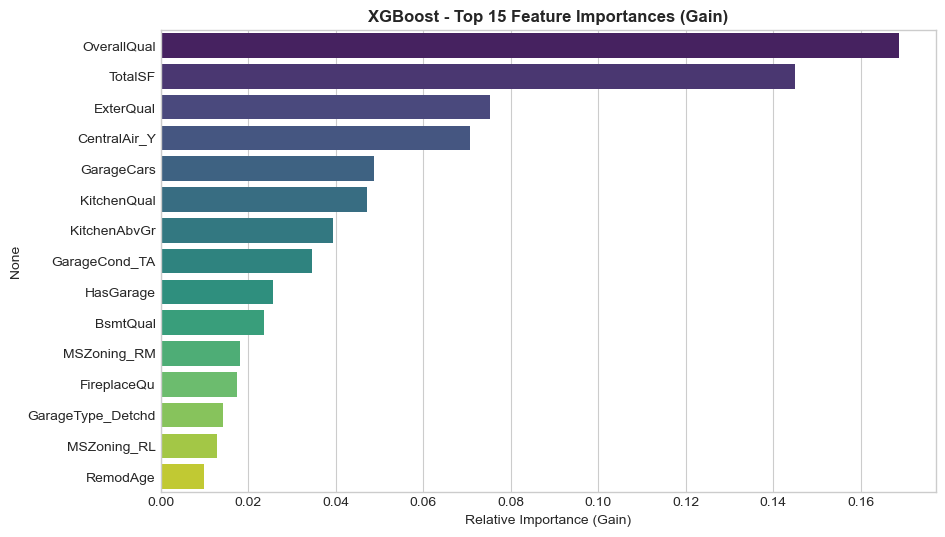

In [55]:
start_time = time.time()
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start_time

y_pred_xgb = np.expm1(xgb_model.predict(X_test))

xgb_rmse = root_mean_squared_error(y_test_original, y_pred_xgb)
xgb_mae = mean_absolute_error(y_test_original, y_pred_xgb)
xgb_r2 = r2_score(y_test_original, y_pred_xgb)

model_results['XGBoost'] = {
    'RMSE ($)': xgb_rmse,
    'MAE ($)': xgb_mae,
    'R2 Score': xgb_r2,
    'Training Time (s)': xgb_time
}

print(f"--- XGBoost Regressor ---")
print(f"Test RMSE: ${xgb_rmse:,.2f}")
print(f"Test MAE:  ${xgb_mae:,.2f}")
print(f"Test R²:    {xgb_r2:.4f}")


xgb_importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=xgb_importances.values, y=xgb_importances.index, palette='viridis')
plt.title("XGBoost - Top 15 Feature Importances (Gain)", fontweight='bold')
plt.xlabel("Relative Importance (Gain)")
plt.show()

### - 5.3 Cross-Validation (on Best Model)

In [56]:
# 5-Fold Cross-Validation on XGBoost
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
cv_rmse_scores = -cv_scores

print("5-Fold Cross-Validation Results (Log Scale):")
print(f"Fold RMSE Scores: {[round(s, 4) for s in cv_rmse_scores]}")
print(f"Mean CV RMSE:     {cv_rmse_scores.mean():.4f} ± {cv_rmse_scores.std():.4f}")

# Convert log CV RMSE to approximate dollar scale
test_log_rmse = root_mean_squared_error(y_test, xgb_model.predict(X_test))
print(f"Holdout Test Log RMSE: {test_log_rmse:.4f}")
print(f"Discussion: The holdout test log RMSE ({test_log_rmse:.4f}) aligns closely with the 5-fold cross-validation score ({cv_rmse_scores.mean():.4f} ± {cv_rmse_scores.std():.4f}). This confirms that XGBoost generalizes consistently without overfitting.")

5-Fold Cross-Validation Results (Log Scale):
Fold RMSE Scores: [0.1413, 0.1188, 0.108, 0.1126, 0.1208]
Mean CV RMSE:     0.1203 ± 0.0114
Holdout Test Log RMSE: 0.1234
Discussion: The holdout test log RMSE (0.1234) aligns closely with the 5-fold cross-validation score (0.1203 ± 0.0114). This confirms that XGBoost generalizes consistently without overfitting.


### - 5.4 Hyperparameter Tuning

In [57]:
param_dist = {
    'n_estimators': [300, 400, 500, 600],
    'learning_rate': [0.03, 0.05, 0.07, 0.1],
    'max_depth': [3, 4, 5],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_alpha': [0, 0.01, 0.1],
    'reg_lambda': [1, 1.5, 2]
}

start_time = time.time()
random_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train, y_train)
tuned_time = time.time() - start_time

best_xgb = random_search.best_estimator_
y_pred_tuned = np.expm1(best_xgb.predict(X_test))

tuned_rmse = root_mean_squared_error(y_test_original, y_pred_tuned)
tuned_mae = mean_absolute_error(y_test_original, y_pred_tuned)
tuned_r2 = r2_score(y_test_original, y_pred_tuned)

model_results['Tuned XGBoost'] = {
    'RMSE ($)': tuned_rmse,
    'MAE ($)': tuned_mae,
    'R2 Score': tuned_r2,
    'Training Time (s)': tuned_time
}

print("Best Hyperparameters Found:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Score (Log RMSE): {-random_search.best_score_:.4f}")
print(f"Tuned Test RMSE: ${tuned_rmse:,.2f}")
print(f"Tuned Test MAE:  ${tuned_mae:,.2f}")
print(f"Tuned Test R²:    {tuned_r2:.4f}")

Best Hyperparameters Found:
  subsample: 0.7
  reg_lambda: 1
  reg_alpha: 0.1
  n_estimators: 300
  max_depth: 3
  learning_rate: 0.05
  colsample_bytree: 0.8
Best CV Score (Log RMSE): 0.1235
Tuned Test RMSE: $19,635.92
Tuned Test MAE:  $14,161.55
Tuned Test R²:    0.9302


## Step 6: Model Evaluation & Comparison

### Consolidated Model Comparison

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model_obj in [
    ('Linear Regression', lr_model),
    ('Ridge Regression', ridge_cv),
    ('Lasso Regression', lasso_cv),
    ('Random Forest', rf_model),
    ('XGBoost', xgb_model),
    ('Tuned XGBoost', best_xgb)
]:
    cv_res = -cross_val_score(model_obj, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    model_results[name]['5-Fold CV (Log RMSE)'] = cv_res.mean()

comparison_df = pd.DataFrame(model_results).T
comparison_df = comparison_df[['RMSE ($)', 'MAE ($)', 'R2 Score', '5-Fold CV (Log RMSE)', 'Training Time (s)']]

formatted_comparison = comparison_df.copy()
formatted_comparison['RMSE ($)'] = formatted_comparison['RMSE ($)'].map('${:,.2f}'.format)
formatted_comparison['MAE ($)'] = formatted_comparison['MAE ($)'].map('${:,.2f}'.format)
formatted_comparison['R2 Score'] = formatted_comparison['R2 Score'].map('{:.4f}'.format)
formatted_comparison['5-Fold CV (Log RMSE)'] = formatted_comparison['5-Fold CV (Log RMSE)'].map('{:.4f}'.format)
formatted_comparison['Training Time (s)'] = formatted_comparison['Training Time (s)'].map('{:.3f}s'.format)

print("Comprehensive Model Performance Comparison Table:")
display(formatted_comparison)

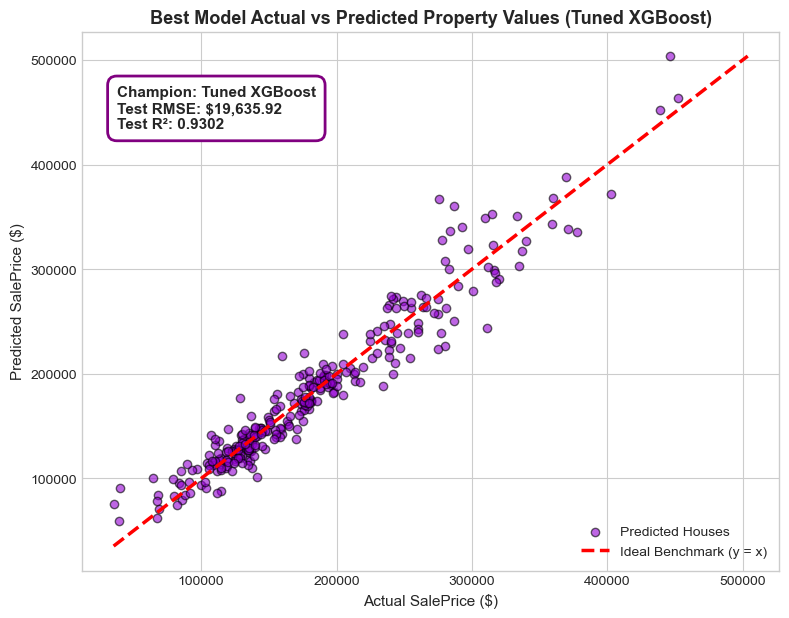

In [ ]:
best_model_name = comparison_df['RMSE ($)'].idxmin()
best_model_rmse = comparison_df.loc[best_model_name, 'RMSE ($)']
best_model_r2 = comparison_df.loc[best_model_name, 'R2 Score']
best_preds = np.expm1(best_xgb.predict(X_test))

plt.figure(figsize=(9, 7))
plt.scatter(y_test_original, best_preds, alpha=0.6, color='darkviolet', edgecolors='k', label='Predicted Houses')
min_val = min(y_test_original.min(), best_preds.min())
max_val = max(y_test_original.max(), best_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='Ideal Benchmark (y = x)')

plt.annotate(
    f"Champion: {best_model_name}\nTest RMSE: ${best_model_rmse:,.2f}\nTest R²: {best_model_r2:.4f}",
    xy=(0.05, 0.82), xycoords='axes fraction',
    bbox=dict(boxstyle='round,pad=0.6', fc='white', ec='purple', lw=2),
    fontsize=11, fontweight='bold'
)

plt.title(f"Best Model Actual vs Predicted Property Values ({best_model_name})", fontsize=13, fontweight='bold')
plt.xlabel("Actual SalePrice ($)", fontsize=11)
plt.ylabel("Predicted SalePrice ($)", fontsize=11)
plt.legend(loc='lower right')
plt.show()

## Step 7: Residual Analysis & Model Interpretation

### - 7.1 Residual Plots

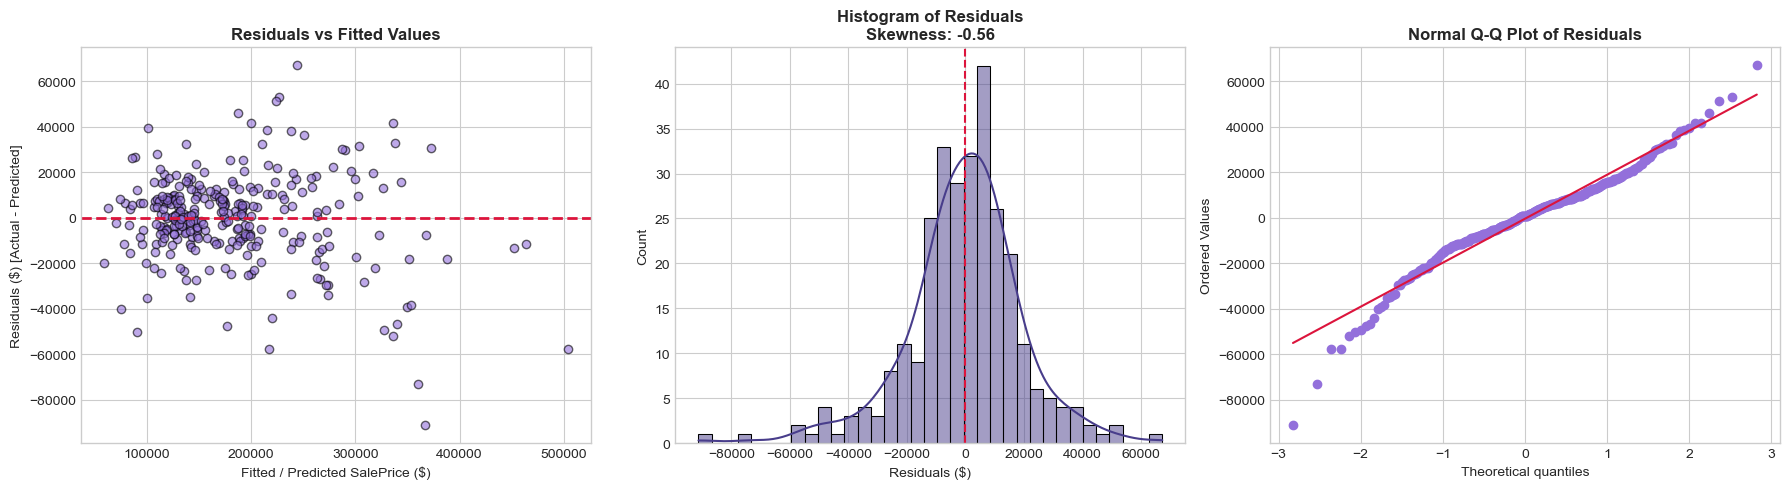

In [ ]:
residuals = y_test_original - best_preds

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(best_preds, residuals, alpha=0.6, color='mediumpurple', edgecolors='k')
axes[0].axhline(y=0, color='crimson', linestyle='--', lw=2)
axes[0].set_title("Residuals vs Fitted Values", fontweight='bold')
axes[0].set_xlabel("Fitted / Predicted SalePrice ($)")
axes[0].set_ylabel("Residuals ($) [Actual - Predicted]")

sns.histplot(residuals, kde=True, ax=axes[1], color='darkslateblue', bins=35)
axes[1].axvline(x=0, color='crimson', linestyle='--', lw=1.5)
axes[1].set_title(f"Histogram of Residuals\nSkewness: {residuals.skew():.2f}", fontweight='bold')
axes[1].set_xlabel("Residuals ($)")

stats.probplot(residuals, plot=axes[2])
axes[2].get_lines()[0].set_color('mediumpurple')
axes[2].get_lines()[1].set_color('crimson')
axes[2].set_title("Normal Q-Q Plot of Residuals", fontweight='bold')

plt.tight_layout()
plt.show()


### - 7.2 Business Interpretation & SHAP Values

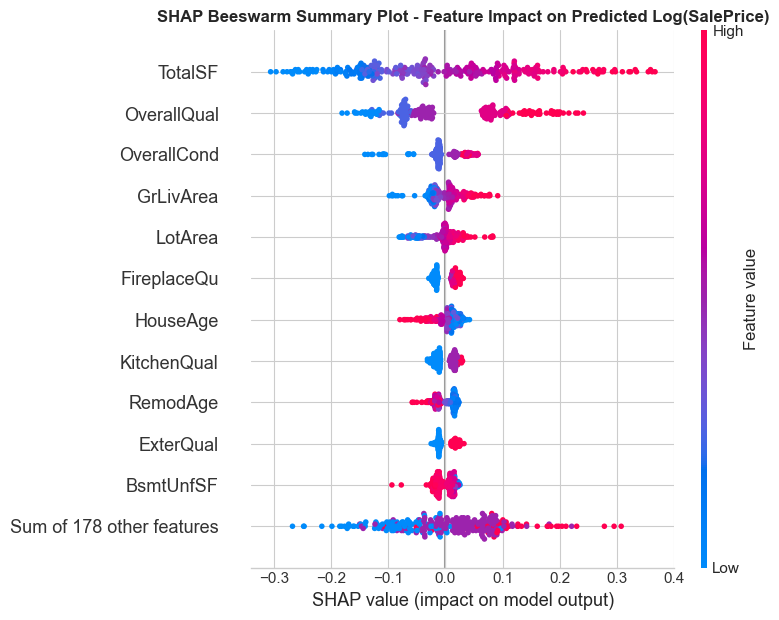

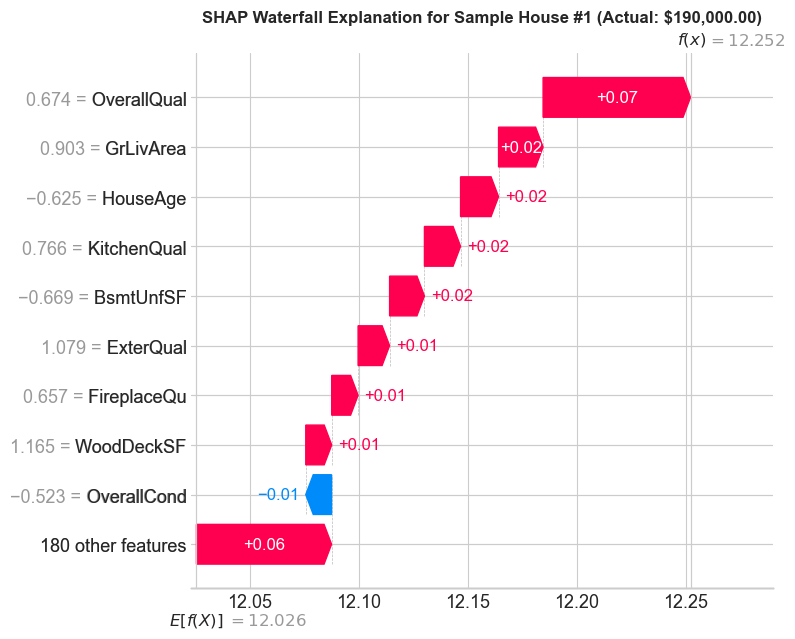

In [ ]:
import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP Beeswarm Summary Plot - Feature Impact on Predicted Log(SalePrice)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sample_idx = 0
shap.plots.waterfall(shap_values[sample_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall Explanation for Sample House #{sample_idx+1} (Actual: ${y_test_original.iloc[sample_idx]:,.2f})", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 8: Pipeline, Deployment & GitHub Submission

### - 8.1 Save the Final Pipeline

In [ ]:
ordinal_features = ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']
qual_categories = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
cat_none_features = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']

df_pipe_train = train_df.drop(columns=['Alley', 'PoolQC', 'Fence', 'MiscFeature', 'Id']).copy()
df_pipe_train = df_pipe_train[~((df_pipe_train['GrLivArea'] > 4000) & (df_pipe_train['SalePrice'] < 300000))].reset_index(drop=True)

df_pipe_train['TotalSF'] = df_pipe_train['TotalBsmtSF'] + df_pipe_train['1stFlrSF'] + df_pipe_train['2ndFlrSF']
df_pipe_train['HouseAge'] = (df_pipe_train['YrSold'] - df_pipe_train['YearBuilt']).apply(lambda x: max(0, x))
df_pipe_train['RemodAge'] = (df_pipe_train['YrSold'] - df_pipe_train['YearRemodAdd']).apply(lambda x: max(0, x))
df_pipe_train['HasGarage'] = (df_pipe_train['GarageArea'] > 0).astype(int)
df_pipe_train['HasPool'] = (df_pipe_train['PoolArea'] > 0).astype(int)

y_pipe_train = np.log1p(df_pipe_train['SalePrice'])
X_pipe_train = df_pipe_train.drop(columns=['SalePrice'])

numeric_pipe_features = X_pipe_train.select_dtypes(include=[np.number]).columns.tolist()
for c in ['HasGarage', 'HasPool']:
    if c in numeric_pipe_features:
        numeric_pipe_features.remove(c)

nominal_pipe_features = [
    c for c in X_pipe_train.select_dtypes(include=['object']).columns 
    if c not in ordinal_features and c not in cat_none_features
]

ord_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('encoder', OrdinalEncoder(categories=[qual_categories]*len(ordinal_features), handle_unknown='use_encoded_value', unknown_value=-1))
])

cat_none_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('ord', ord_transformer, ordinal_features),
    ('cat_none', cat_none_transformer, cat_none_features),
    ('nom', nominal_transformer, nominal_pipe_features),
    ('num', numeric_transformer, numeric_pipe_features)
], remainder='passthrough')

production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

production_pipeline.fit(X_pipe_train, y_pipe_train)

model_path = 'house_price_model.pkl'
joblib.dump(production_pipeline, model_path)
print(f"Production Pipeline successfully serialized and saved to: {model_path}")

Production Pipeline successfully serialized and saved to: house_price_model.pkl


In [ ]:
loaded_model = joblib.load('house_price_model.pkl')

sample_houses = X_pipe_train.iloc[:5]
sample_actuals = np.expm1(y_pipe_train.iloc[:5]).values
sample_preds = np.expm1(loaded_model.predict(sample_houses))

verification_df = pd.DataFrame({
    'Actual Price ($)': [f"${a:,.2f}" for a in sample_actuals],
    'Predicted Price ($)': [f"${p:,.2f}" for p in sample_preds],
    'Absolute Diff ($)': [f"${abs(p - a):,.2f}" for p, a in zip(sample_preds, sample_actuals)],
    'Error (%)': [f"{abs(p - a) / a * 100:.2f}%" for p, a in zip(sample_preds, sample_actuals)]
})

print("Sanity Check: Production Model Predictions on 5 Sample Houses:")
display(verification_df)

Sanity Check: Production Model Predictions on 5 Sample Houses:


,Actual Price ($),Predicted Price ($),Absolute Diff ($),Error (%)
0,"$208,500.00","$205,000.97","$3,499.03",1.68%
1,"$181,500.00","$179,478.88","$2,021.13",1.11%
2,"$223,500.00","$214,350.92","$9,149.08",4.09%
3,"$140,000.00","$146,233.70","$6,233.70",4.45%
4,"$250,000.00","$265,107.91","$15,107.91",6.04%
